# Getting to know your data

**Worksheet · Data 110 · Fall 2026 · Week 10**
Rebin Muhammad

**Enda Hughes**


## Setup

Python’s standard library reads and summarizes the CSV.


In [1]:
import csv
from pathlib import Path
from statistics import mean
from urllib.request import urlopen


## The file

`NCbirths.csv` has one row per birth. There are 1,450 rows and 15 columns. The rows are a sample of births in North Carolina in 2001.

Empty cells and `#N/A` are read as missing values. The sentinel `-999` remains in `Weeks` until exercise 4.


In [2]:
csv_path = Path("NCbirths.csv")
course_csv = "https://raw.githubusercontent.com/Reben80/Data110-Fall2026-CRN21802/main/dataset/NCbirths.csv"
if csv_path.is_file():
    csv_text = csv_path.read_text(encoding="utf-8-sig")
else:
    with urlopen(course_csv) as response:
        csv_text = response.read().decode("utf-8-sig")
reader = csv.DictReader(csv_text.splitlines())
columns = reader.fieldnames
births = [
    {column: None if value.strip() in {"", "#N/A"} else value
     for column, value in row.items()}
    for row in reader
]
births[:5]


[{'ID': '1',
  'Plural': '1',
  'Sex': '1',
  'MomAge': '32',
  'Weeks': '40',
  'Marital': '1',
  'RaceMom': '1',
  'HispMom': 'N',
  'Gained': '38',
  'Smoke': '0',
  'BirthWeightOz': '111',
  'BirthWeightGm': '3146.85',
  'Low': '0',
  'Premie': '0',
  'MomRace': 'white'},
 {'ID': '2',
  'Plural': '1',
  'Sex': '2',
  'MomAge': '32',
  'Weeks': '37',
  'Marital': '1',
  'RaceMom': '1',
  'HispMom': 'N',
  'Gained': '34',
  'Smoke': '0',
  'BirthWeightOz': '116',
  'BirthWeightGm': '3288.6',
  'Low': '0',
  'Premie': '0',
  'MomRace': 'white'},
 {'ID': '3',
  'Plural': '1',
  'Sex': '1',
  'MomAge': '27',
  'Weeks': '39',
  'Marital': '1',
  'RaceMom': '1',
  'HispMom': 'N',
  'Gained': '12',
  'Smoke': '0',
  'BirthWeightOz': '138',
  'BirthWeightGm': '3912.3',
  'Low': '0',
  'Premie': '0',
  'MomRace': 'white'},
 {'ID': '4',
  'Plural': '1',
  'Sex': '1',
  'MomAge': '27',
  'Weeks': '39',
  'Marital': '1',
  'RaceMom': '1',
  'HispMom': 'N',
  'Gained': '15',
  'Smoke': '0',
  'B

## 1. How big is the table?

**Exercise.** Print the number of rows and the number of columns.

`shape` is a pair: rows, then columns.

### Your solution

Write your code in the next cell, then run it.


In [3]:
print(f"Rows: {len(births)}")
print(f"Columns: {len(columns)}")


Rows: 1450
Columns: 15


## 2. Where are the blanks?

**Exercise.** Count the missing values in every column.

`isna` is `True` on a blank cell. `sum` counts those `True` values in each column. A blank is not the same thing as a number such as `-999`.

### Your solution

Write your code in the next cell, then run it.


In [4]:
for column in columns:
    missing = sum(row[column] is None for row in births)
    print(f"{column}: {missing}")


ID: 0
Plural: 0
Sex: 0
MomAge: 0
Weeks: 0
Marital: 0
RaceMom: 0
HispMom: 0
Gained: 40
Smoke: 0
BirthWeightOz: 0
BirthWeightGm: 0
Low: 0
Premie: 0
MomRace: 0


## 3. The week that cannot be a gestation

**Exercise.** Show the rows where `Weeks` is below 0, and print how many such rows there are.

A completed pregnancy is not a negative number of weeks. In this file that negative number is `-999`.

### Your solution

Write your code in the next cell, then run it.


In [5]:
negative_weeks = [
    row for row in births if row["Weeks"] is not None and int(row["Weeks"]) < 0
]
print(f"Rows with negative Weeks: {len(negative_weeks)}")
negative_weeks


Rows with negative Weeks: 1


[{'ID': '1118',
  'Plural': '1',
  'Sex': '1',
  'MomAge': '20',
  'Weeks': '-999',
  'Marital': '2',
  'RaceMom': '2',
  'HispMom': 'N',
  'Gained': None,
  'Smoke': '0',
  'BirthWeightOz': '136',
  'BirthWeightGm': '3855.6',
  'Low': '0',
  'Premie': '1',
  'MomRace': 'black'}]

## 4. Turn the sentinel into a blank

**Exercise.** On a copy of the table, replace every negative `Weeks` with a missing value. Then print the minimum and the mean of `Weeks`.

`copy` keeps the original `births` table unchanged. `loc` selects the rows. `pd.NA` is a blank. `mean` skips blanks, so the mean changes once `-999` is no longer a number.

### Your solution

Write your code in the next cell, then run it.


In [6]:
births_clean = [row.copy() for row in births]
for row in births_clean:
    if row["Weeks"] is not None:
        weeks = int(row["Weeks"])
        row["Weeks"] = weeks if weeks >= 0 else None

valid_weeks = [row["Weeks"] for row in births_clean if row["Weeks"] is not None]
print(f"Minimum: {min(valid_weeks)} weeks")
print(f"Mean: {mean(valid_weeks):.2f} weeks")


Minimum: 22 weeks
Mean: 38.62 weeks


## 5. Turn the sex code into a word

**Exercise.** Add a column `sex_word`. Code `1` becomes `male` and code `2` becomes `female`. Then count the two words.

`map` looks up each number in a dictionary. Use `{1: "male", 2: "female"}`.

### Your solution

Write your code in the next cell, then run it.


In [7]:
sex_words = {1: "male", 2: "female"}
for row in births_clean:
    row["sex_word"] = sex_words.get(int(row["Sex"])) if row["Sex"] is not None else None
for word in sex_words.values():
    print(f"{word}: {sum(row['sex_word'] == word for row in births_clean)}")


male: 744
female: 706


## 6. The shape of the real weeks

**Exercise.** Draw a histogram of `Weeks` after the negative value has been replaced with a blank. Use bins that are one week wide. Label the horizontal axis `completed weeks` and the vertical axis `births`.

Drop the blank before you draw, with `dropna`. One bar per week is `bins` set to a sequence of edges one week apart. The real weeks run from 22 to 45.

### Your solution

Write your code in the next cell, then run it.


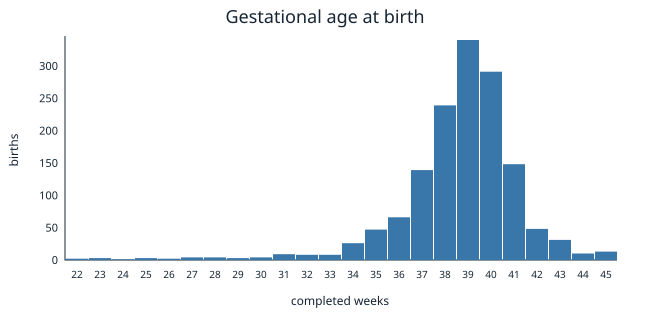

In [8]:
from collections import Counter

week_counts = Counter(valid_weeks)
week_bins = range(min(valid_weeks), max(valid_weeks) + 1)
scale = 220 / max(week_counts.values())
parts = [
    '<svg xmlns="http://www.w3.org/2000/svg" width="650" height="325" viewBox="0 0 650 325">',
    '<rect width="650" height="325" fill="white"/>',
    '<g font-family="sans-serif" fill="#172534">',
    '<text x="325" y="23" text-anchor="middle" font-size="18">Gestational age at birth</text>',
    '<path d="M65 36 V260 H617" stroke="#172534" fill="none"/>',
    '<text x="340" y="305" text-anchor="middle">completed weeks</text>',
    '<text x="18" y="150" text-anchor="middle" transform="rotate(-90 18 150)">births</text>',
]
for count in range(0, max(week_counts.values()) + 1, 50):
    y = 260 - count * scale
    parts.append(f'<text x="58" y="{y + 4:.1f}" text-anchor="end" font-size="11">{count}</text>')
for i, week in enumerate(week_bins):
    x = 66 + i * 23
    height = week_counts[week] * scale
    parts.append(f'<rect x="{x}" y="{260 - height:.1f}" width="22" height="{height:.1f}" fill="#3976aa"/>')
    parts.append(f'<text x="{x + 11}" y="278" text-anchor="middle" font-size="10">{week}</text>')
parts.append("</g></svg>")

class Histogram:
    def _repr_svg_(self):
        return "".join(parts)

Histogram()
